In [107]:
# Data libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import sklearn.pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


### i added doy: (d)ay (o)f (y)ear then i did sine and cosine (claudes suggestion)
### i defined the below as global variables
### i added comments in the functions
### in IQR i modified a little

In [37]:
labels = ["avg", "min", "max"]
cutoff = pd.Timestamp("2026-08-31")

In [38]:
def reshape_long(avg_df, min_df, max_df, loc_df, start = "2017-04-01", drop_tidal = True):
    """
    Input:
    - avg_df, min_df, max_df: Average, Minimum and Maximum df
    - loc_df: locations df
    - start: observations before this date will be removed
    - drop_tidal: boolean value, should tidal-level stations be removed
    Returns: 
    - river long df: df with one row per station per day and columns
    """
    data = [avg_df, min_df, max_df]  
    column = ["County", "Station_Name", "Observation_ID", "date"]
    long_df = {}

    for df, lab in zip(data, labels):
        if drop_tidal:
            df = df[~df["Observation_ID"].str.contains("tidal-level", na = False)]  
        
        long_df[lab] = df.melt(id_vars = column[0:3], var_name = "date", value_name = lab)
        long_df[lab]["date"] = pd.to_datetime(long_df[lab]["date"], format = "%d/%m/%Y")
        long_df[lab] = long_df[lab][long_df[lab]["date"] >= start]

    river_long = (long_df["avg"]
                 .merge(long_df["min"], on = column, how = "left")
                 .merge(long_df["max"], on = column, how = "left")
                 .merge(loc_df, on = column[0:3], how = "left"))

    for col in column[0:3]:
        river_long[col] = river_long[col].astype("category")
    
    return river_long

In [44]:
def clean_error(df, k = 20):
    """
    Input: 
    - df: long data frame that contains Observation_ID, date, avg, min, max
    - k: number of IQRs beyond Q1/Q3 at which a value is an outlier
    Returns:
    - df2 : a copy of the df with the bad values replaced by NaN values
    """
    df2 = df.copy()

    large_vals = df2[labels].isin([99999.999, -999999.999, -99]) | (df2[labels].abs() >= 9999)
    err = large_vals.any(axis=1)
    # here .any(axis=1) cuz it looks at each row and put it whole NaN
    print("large_vals rows:", int(err.sum()))
    df2.loc[err, labels] = np.nan


    for lab in labels:
        train_val = df2[lab].where(df2["date"] <= cutoff)
        per_sta = train_val.groupby(df2["Observation_ID"], observed = True)

        q1 = per_sta.transform(lambda s: s.quantile(0.25))
        q3 = per_sta.transform(lambda s: s.quantile(0.75))
        sd = per_sta.transform("std")

        # if iqr = 0 we use std
        iqr = (q3 - q1).where(q3 - q1 > 0, sd)
        
        outlier = ((df2[lab] > q3 + k * iqr) | (df2[lab] < q1 - k * iqr))
        df2.attrs[f"outliers_{lab}"] = int(outlier.sum())        
        df2.loc[outlier, lab] = np.nan

    bad = (df2["min"] > df2["avg"]) | (df2["avg"] > df2["max"])
    df2.attrs["order_violations"] = int(bad.sum())
    df2.loc[bad, labels] = np.nan
        
    return df2

In [45]:
def drop_ids(df, min_years = 3, cutoff = cutoff, recent_from="2026-06-01"):
    """
    Input:
    - df: long cleaned data fram: contains Observation_ID, date, avg
    - min_years: minimum number of years of non missing avg data a station needs to be kept
    cutoff: data that marks the end of the period (given from the question)
    Return:
    - keep_df: a copy of df containing only stations we keep
    """
    train_obs = df["avg"].notna() & (df["date"] <= pd.Timestamp(cutoff))
    years = train_obs.groupby(df["Observation_ID"], observed = True).sum() / 365.25


    keep_ids = years[years >= min_years].index

    keep_df = df[df["Observation_ID"].isin(keep_ids)].copy()
    keep_df.attrs["dropped_ids"] = int((years < min_years).sum())
    keep_df.attrs["kept_ids"] = int((years >= min_years).sum())

    return keep_df

In [46]:
def make_split(clean_df, cutoff = "2026-08-31",
               feature_cols = ["Latitude", "Longitude"], target = "avg"):
    """
    Input:
    - clean_df: a long data frame containing  Observation_ID, date, the feature columns and the target column
    - cutoff: last day of training period
    - feature_cols: list of features names
    - target: target name to preidct
    Returns:
    - X_train
    - y_train
    - X_test
    - y_test
    """
    cutoff = pd.Timestamp(cutoff)

    # split by cutoff date
    train = clean_df[clean_df["date"] <= cutoff]
    test  = clean_df[clean_df["date"] > cutoff]

    # drop rows with no target, then sort + renumber
    train = train.dropna(subset = [target]).sort_values(["Observation_ID", "date"]).reset_index(drop = True)
    test  = test.dropna(subset = [target]).sort_values(["Observation_ID", "date"]).reset_index(drop = True)

    X_train, y_train = train[feature_cols], train[target]
    X_test,  y_test  = test[feature_cols],  test[target]

    return X_train, y_train, X_test, y_test

In [48]:
# Load data

river_avg = pd.read_csv("avg_river_levels.csv")
river_min = pd.read_csv("min_river_levels.csv")
river_max = pd.read_csv("max_river_levels.csv")

river_location = pd.read_csv("monitoring_locations.csv")

In [49]:
# Data cleaning 

river_long = reshape_long(river_avg, river_min, river_max, river_location)
river_long2 = clean_error(river_long)
river_long3 = drop_ids(river_long2)

print(river_long2.attrs)
print(river_long3.attrs)

# Split data 

X_train, y_train, X_test, y_test = make_split(river_long3)


large_vals rows: 78
{'outliers_avg': 112, 'outliers_min': 179, 'outliers_max': 145, 'order_violations': 0}
{'outliers_avg': 112, 'outliers_min': 179, 'outliers_max': 145, 'order_violations': 0, 'dropped_ids': 8, 'kept_ids': 372}


Here, we do some EDA

In [50]:
pred_grid

,Observation_ID,date,avg
0,aberdeenshire__bogie-redcraig__obs1,2026-09-01,0.125
1,aberdeenshire__bogie-redcraig__obs1,2026-09-02,0.120
2,aberdeenshire__bogie-redcraig__obs1,2026-09-03,0.118
3,aberdeenshire__bogie-redcraig__obs1,2026-09-04,0.110
4,aberdeenshire__bogie-redcraig__obs1,2026-09-05,0.110
...,...,...,...
33847,wigtown__white-laggan-white-laggan__obs1,2026-11-26,NaN
33848,wigtown__white-laggan-white-laggan__obs1,2026-11-27,NaN
33849,wigtown__white-laggan-white-laggan__obs1,2026-11-28,NaN
33850,wigtown__white-laggan-white-laggan__obs1,2026-11-29,NaN


In [52]:
train_df = river_long3[river_long3["date"] <= cutoff].copy()
train_df.info()
train_df[labels].describe()
train_df[labels].isna().sum()


<class 'pandas.DataFrame'>
Index: 1279680 entries, 0 to 1307199
Data columns (total 9 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   County          1279680 non-null  category      
 1   Station_Name    1279680 non-null  category      
 2   Observation_ID  1279680 non-null  category      
 3   date            1279680 non-null  datetime64[us]
 4   avg             1129123 non-null  float64       
 5   min             1129059 non-null  float64       
 6   max             1129090 non-null  float64       
 7   Latitude        1279680 non-null  float64       
 8   Longitude       1279680 non-null  float64       
dtypes: category(3), datetime64[us](1), float64(5)
memory usage: 74.5 MB


avg    150557
min    150621
max    150590
dtype: int64

There are still missing values, we need to find another soln

In [60]:
train_df[labels].describe()

,avg,min,max
count,1.129123e+06,1.129059e+06,1.129090e+06
mean,6.806142e-01,5.777855e-01,8.014639e-01
std,1.516476e+00,1.506252e+00,1.579950e+00
min,-6.620000e+00,-8.891000e+00,-6.620000e+00
25%,2.900000e-01,2.550000e-01,3.200000e-01
50%,4.710000e-01,4.300000e-01,5.240000e-01
75%,7.400000e-01,6.600000e-01,8.800000e-01
max,3.424300e+01,3.419000e+01,3.439000e+01


In [53]:
print("Stations:", train_df["Observation_ID"].nunique())
print("Counties:", train_df["County"].nunique())
print("Dates:", train_df["date"].min().date(), "to", train_df["date"].max().date())


Stations: 372
Counties: 35
Dates: 2017-04-01 to 2026-08-31


In [61]:
train_df.groupby("month")["avg"].describe()

,count,mean,std,min,25%,50%,75%,max
month,,,,,,,,
1,85304.0,0.806279,1.541739,-3.000,0.381,0.579,0.887,30.956
2,77542.0,0.811507,1.438894,-3.683,0.394,0.602,0.908,30.888
3,79080.0,0.743068,1.491443,-2.579,0.356,0.540,0.813,30.405
4,93593.0,0.619930,1.441187,-1.750,0.276,0.433,0.657,31.162
5,96650.0,0.533218,1.493790,-6.131,0.217,0.354,0.533,31.870
6,103828.0,0.554673,1.534254,-2.995,0.223,0.373,0.565,34.243
7,107929.0,0.550966,1.523683,-2.010,0.217,0.364,0.560,30.248
8,108420.0,0.598465,1.521156,-6.620,0.241,0.405,0.631,30.225
9,94248.0,0.630912,1.513950,-1.729,0.264,0.432,0.675,30.670


Now, we do some EDA

In [62]:
train_df = train_df.sort_values(["Observation_ID", "date"]).copy()
per_sta = train_df.groupby("Observation_ID", observed = True)["avg"]
train_df["z"] = (train_df["avg"] - per_sta.transform("mean")) / per_sta.transform("std")
train_df["year"] = train_df["date"].dt.year
train_df["month"] = train_df["date"].dt.month
train_df["doy"] = train_df["date"].dt.dayofyear

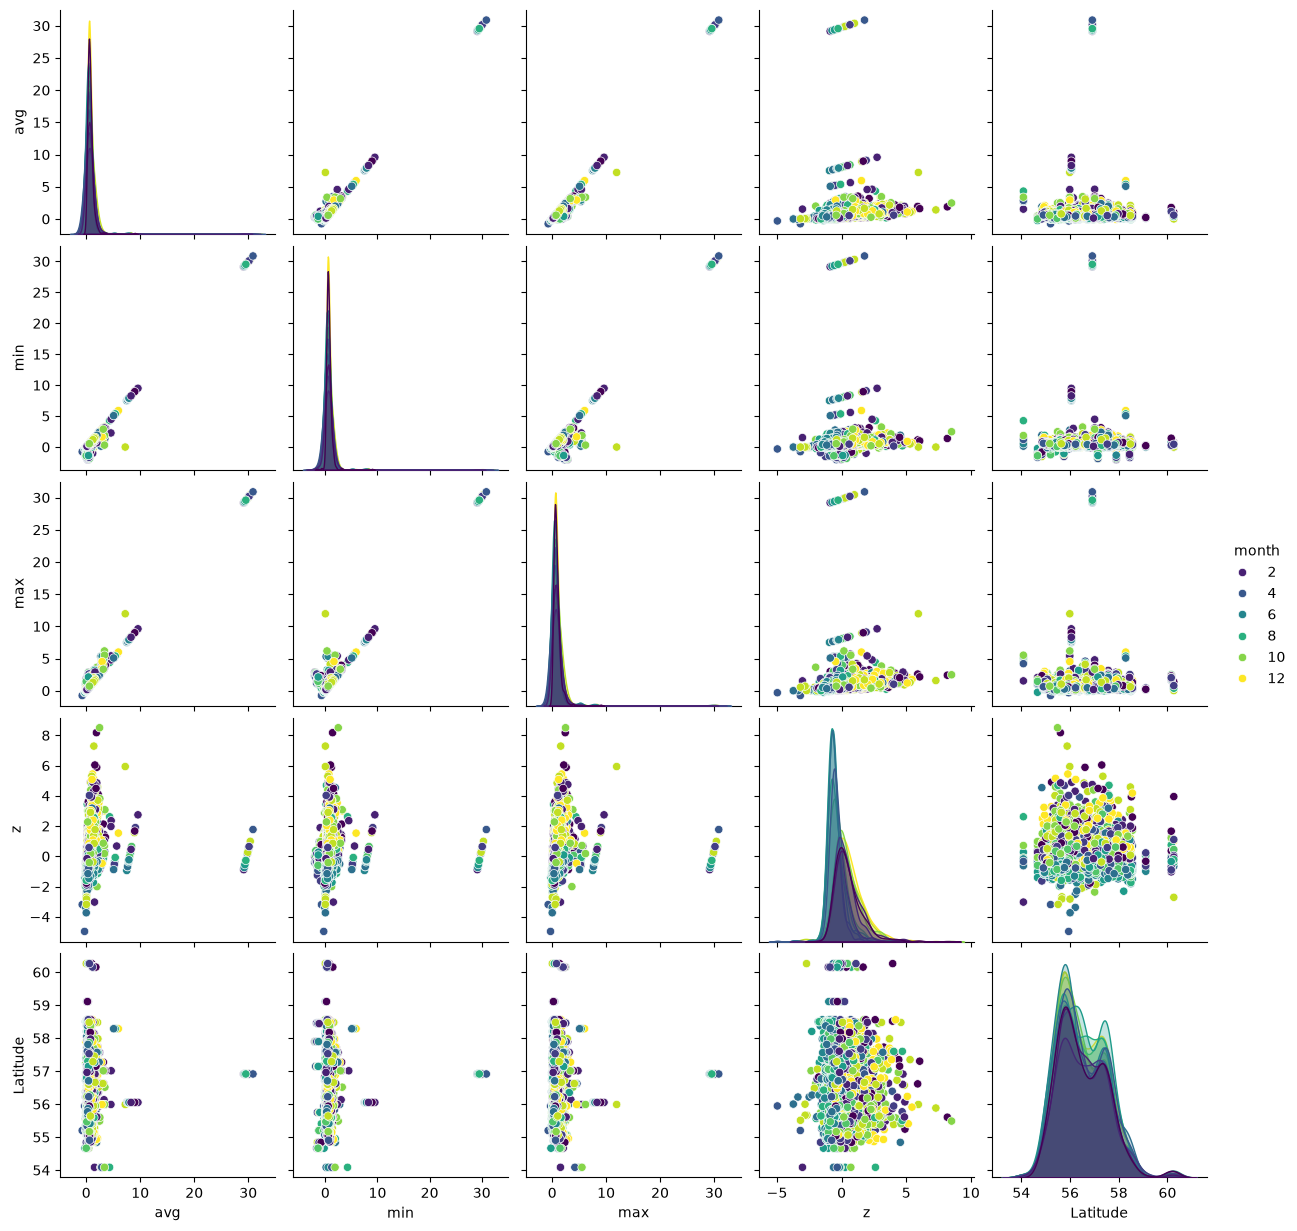

In [81]:
sample = train_df.dropna(subset = ["avg"]).sample(5000, random_state = 0)
sns.pairplot(sample, vars = ["avg", "min", "max", "z", "Latitude"], hue = "month", palette = "viridis")
plt.show()

Daily min, avd, and max levels are linearly related.
Latidue has no clear relation with z.

In [67]:
sample.columns

Index(['County', 'Station_Name', 'Observation_ID', 'date', 'avg', 'min', 'max',
       'Latitude', 'Longitude', 'month', 'year', 'z', 'doy'],
      dtype='str')

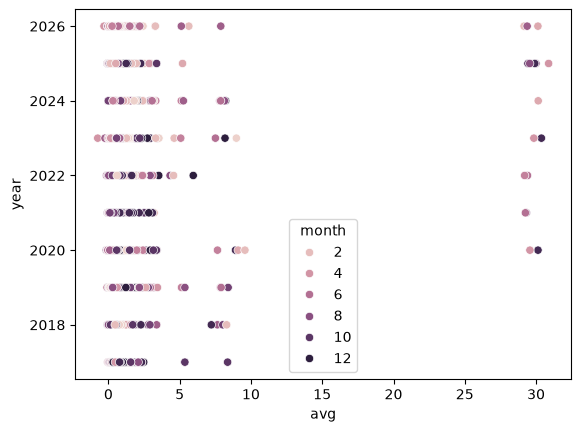

In [70]:
sns.scatterplot(data = sample, x = "avg", y="year", hue="month")
plt.show()

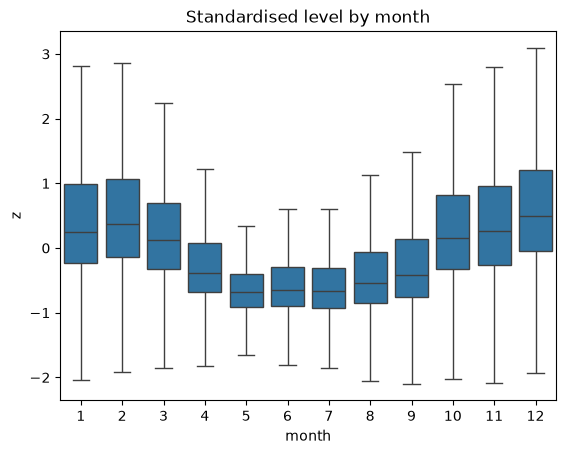

In [75]:
sns.boxplot(data = train_df, x = "month", y = "z", showfliers = False)
plt.title("Standardised level by month")

plt.show()

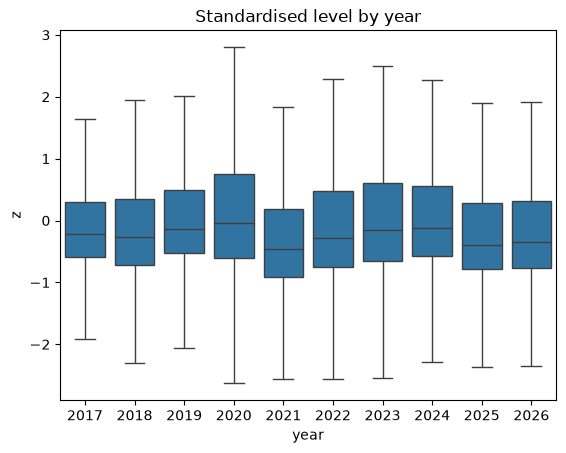

In [76]:
sns.boxplot(data = train_df, x = "year", y = "z", showfliers = False)
plt.title("Standardised level by year")
plt.show()

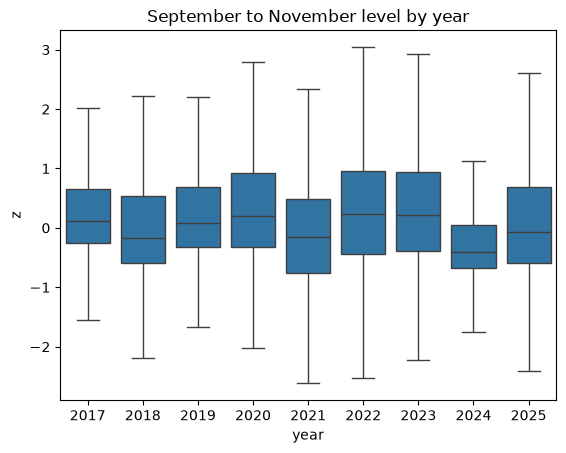

In [77]:
autumn = train_df[train_df["month"].isin([9, 10, 11])]
sns.boxplot(data = autumn, x = "year", y = "z", showfliers = False)
plt.title("September to November level by year")
plt.show()

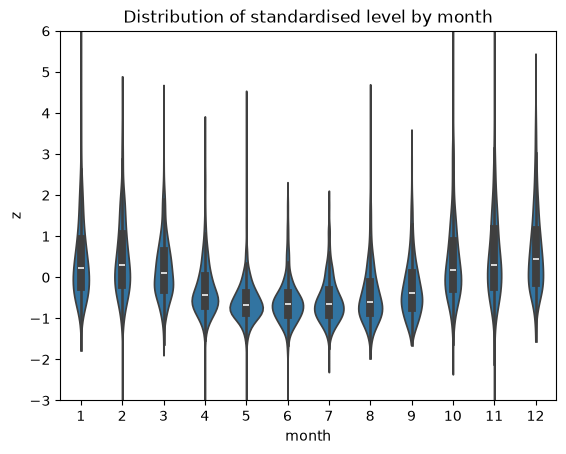

In [82]:
sns.violinplot(data = sample, x = "month", y = "z", cut = 0)
plt.ylim(-3, 6)
plt.title("Distribution of standardised level by month")
plt.show()

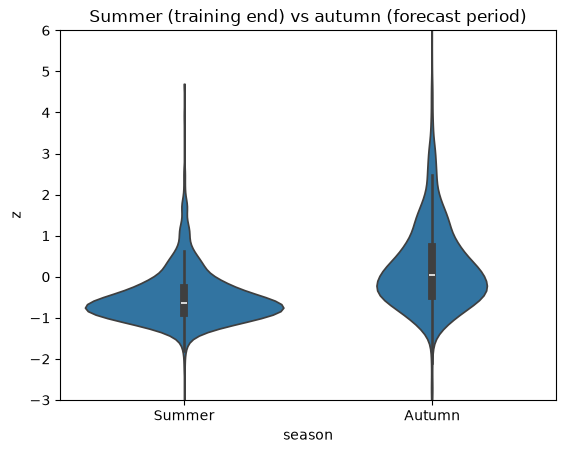

In [84]:
# TO REMEMBER: i used this idea from claude !!!
sample["season"] = sample["month"].map({6: "Summer", 7: "Summer", 8: "Summer",
                                        9: "Autumn", 10: "Autumn", 11: "Autumn"})

sns.violinplot(data = sample.dropna(subset = ["season"]), x = "season", y = "z", cut = 0)
plt.ylim(-3, 6)
plt.title("Summer (training end) vs autumn (forecast period)")
plt.show()

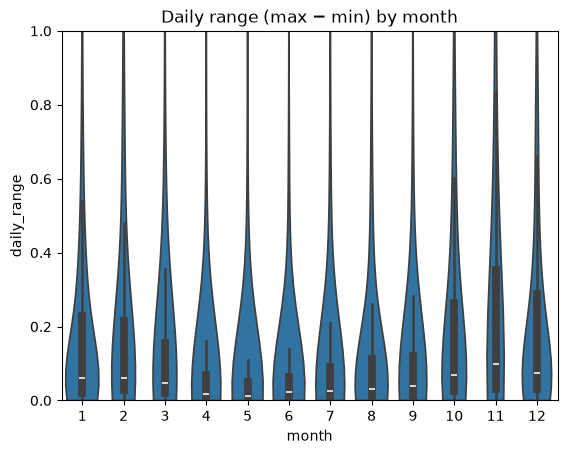

In [85]:
sample["daily_range"] = sample["max"] - sample["min"]

sns.violinplot(data = sample, x = "month", y = "daily_range", cut = 0)
plt.ylim(0, 1)
plt.title("Daily range (max − min) by month")
plt.show()

We create a baseline model

In [90]:
# i used function from lab 5
def get_coefs(m, plot = False, feature_names = None, figsize = (5,5), figtitle = None, intercept = True):
    """Returns model coefficients in a data frame for a fitted linear model.
    
    Args:
        m: sklearn LinearRegression model object or pipeline with LinearRegression as final step
        plot: boolean value, should coefficients be plotted with error bars
        feature_names: list of feature names to use in the plot 
        figsize: tuple defining figure size
        figtitle: string defining figure title
        intercept: boolean value, should intercept be included in the plot
    """
    
    # Extract intercept and coefficients into a single array
    w = np.concatenate(([m[-1].intercept_] if isinstance(m, sklearn.pipeline.Pipeline) else [m.intercept_], 
                            m[-1].coef_ if isinstance(m, sklearn.pipeline.Pipeline) else m.coef_))
    # Extract name of features
    if feature_names is None:
        feature_names = m[:-1].get_feature_names_out() if isinstance(m, sklearn.pipeline.Pipeline) else m.feature_names_in_
    feature_names = np.concatenate((['intercept'], feature_names))
    # Create a data frame
    w_df = pd.DataFrame({'feature': feature_names, 'coef': w}).sort_values ("coef", ascending=False)

    if plot:
        if not intercept:
            w_df = w_df[w_df['feature'] != 'intercept']
        plt.figure(figsize=figsize)
        plt.barh(w_df['feature'], w_df['coef'])
        plt.ylabel('Features')
        plt.xlabel('Coefficient Value')
        plt.axvline(x=0, color=".5")
        if figtitle is not None:
            plt.title(figtitle)
        plt.grid()
        plt.show()
    
    return  w_df




In [ ]:
"""lm = LinearRegression().fit(X_train, y_train)
w_df = get_coefs(lm, plot=True, figsize=(6,6), figtitle="Linear Regression", intercept=False)"""

In [113]:
# claude suggested we use cosine and sine for periodicity
def add_features(df):
    """
    Input:
    - df: a long dataframe containing  containing Observation_ID, date and avg
    Returns:
    - df2: a copy of df with columns added:
            * sta_mean: stations mean avg level
            * sta_std: stations stdev avg level
            * z: standardised level
            * sin_doy, cos_doy: sin and cos of the day od the year scaled to one full cycle per year
    """
    df2 = df.copy()    
    train_val = df2["avg"].where(df2["date"] <= cutoff)
    per_sta = train_val.groupby(df2["Observation_ID"], observed = True)
    df2["sta_mean"] = per_sta.transform("mean")
    df2["sta_std"] = per_sta.transform("std")
    df2["z"] = (df2["avg"] - df2["sta_mean"]) / df2["sta_std"]
    doy = df2["date"].dt.dayofyear
    df2["sin_doy"] = np.sin(2 * np.pi * doy / 365.25)
    df2["cos_doy"] = np.cos(2 * np.pi * doy / 365.25)
    return df2


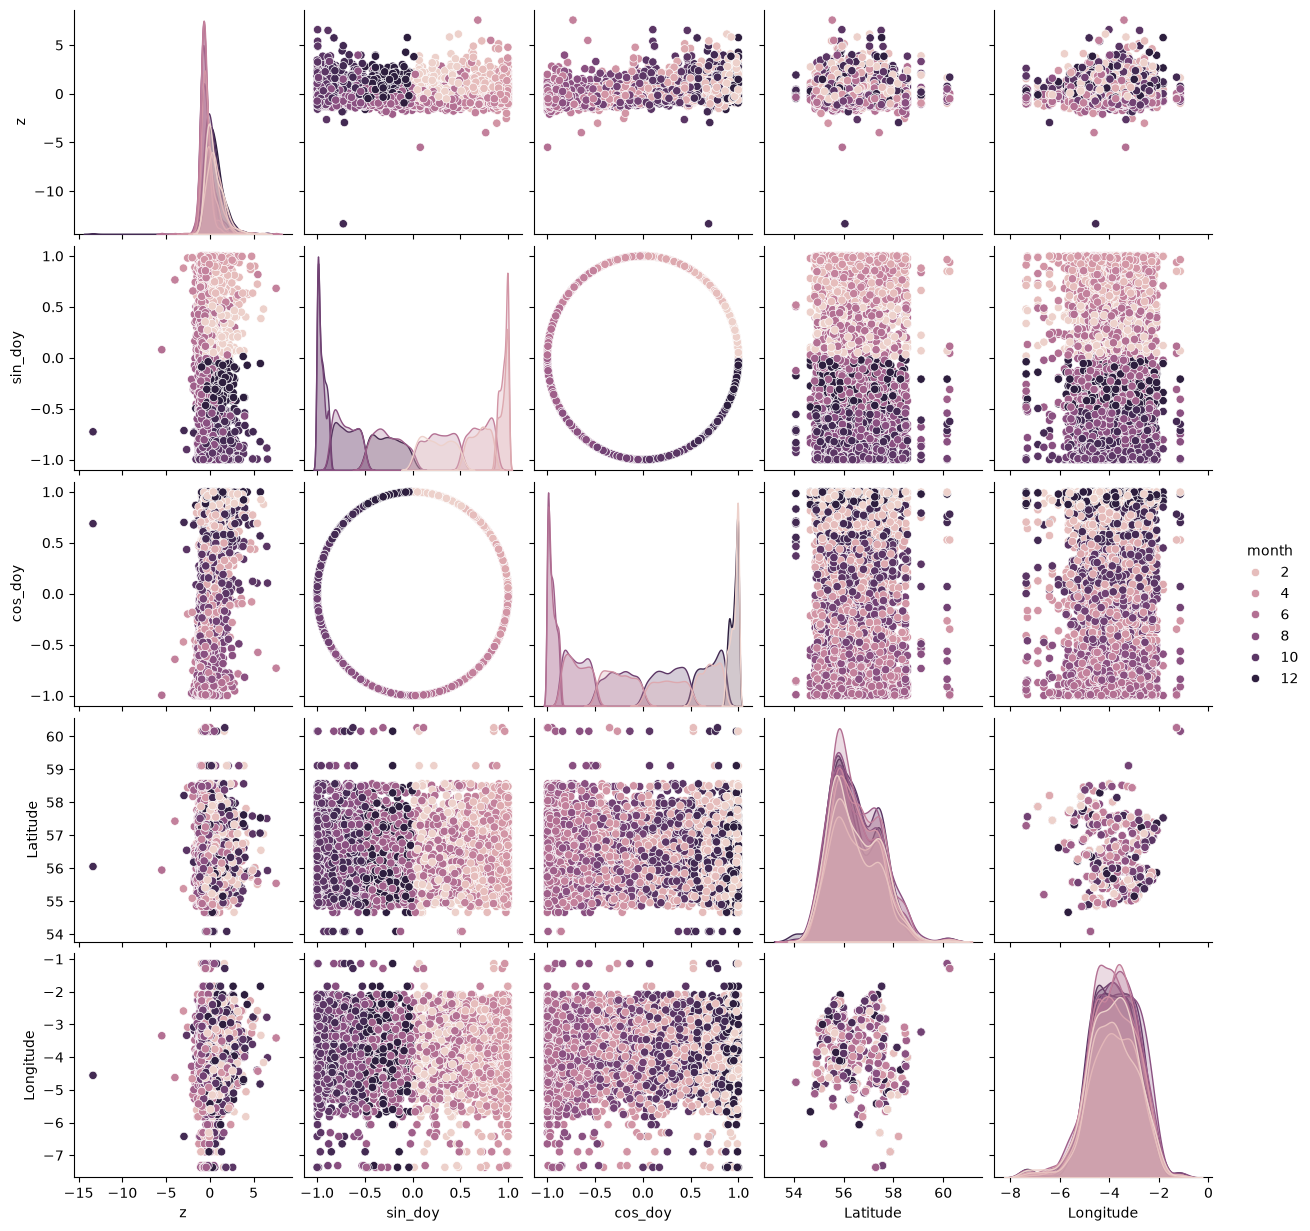

In [114]:
river_feat = add_features(river_long3)
X_train, y_train, X_test, y_test = make_split(river_feat, feature_cols = ["sin_doy", "cos_doy"], target = "z")

sample = (river_feat[river_feat["date"] <= cutoff]
          .dropna(subset = ["z"])
          .sample(5000, random_state = 0))
sample["month"] = sample["date"].dt.month
sns.pairplot(sample, vars = ["z", "sin_doy", "cos_doy", "Latitude", "Longitude"],
             hue = "month")
plt.show()

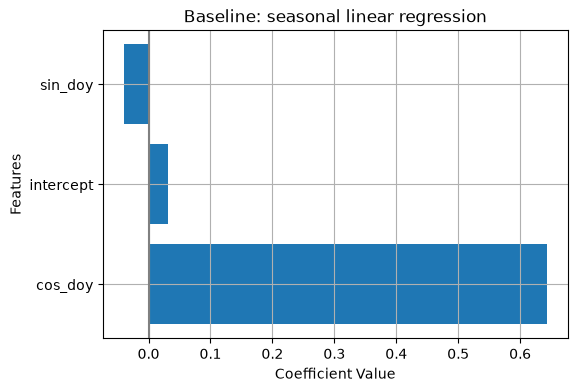

     feature      coef
2    cos_doy  0.642912
0  intercept  0.031519
1    sin_doy -0.039638


In [115]:
lm = LinearRegression().fit(X_train, y_train)
w_df = get_coefs(lm, plot = True, figsize = (6, 4), figtitle = "Baseline: seasonal linear regression")
print(w_df)

In [116]:

test_df = (river_feat[river_feat["date"] > cutoff]
           .dropna(subset = ["z"])
           .sort_values(["Observation_ID", "date"])
           .reset_index(drop = True))

pred_z = lm.predict(X_test)
pred_m = pred_z * test_df["sta_std"] + test_df["sta_mean"]

print("RMSE (z):", root_mean_squared_error(y_test, pred_z))
print("RMSE (m):", root_mean_squared_error(test_df["avg"], pred_m))
print("MAE (m): ", mean_absolute_error(test_df["avg"], pred_m))

RMSE (z): 0.7699697129758024
RMSE (m): 0.18862803387015803
MAE (m):  0.13633949928906314


### Baseline model with all features

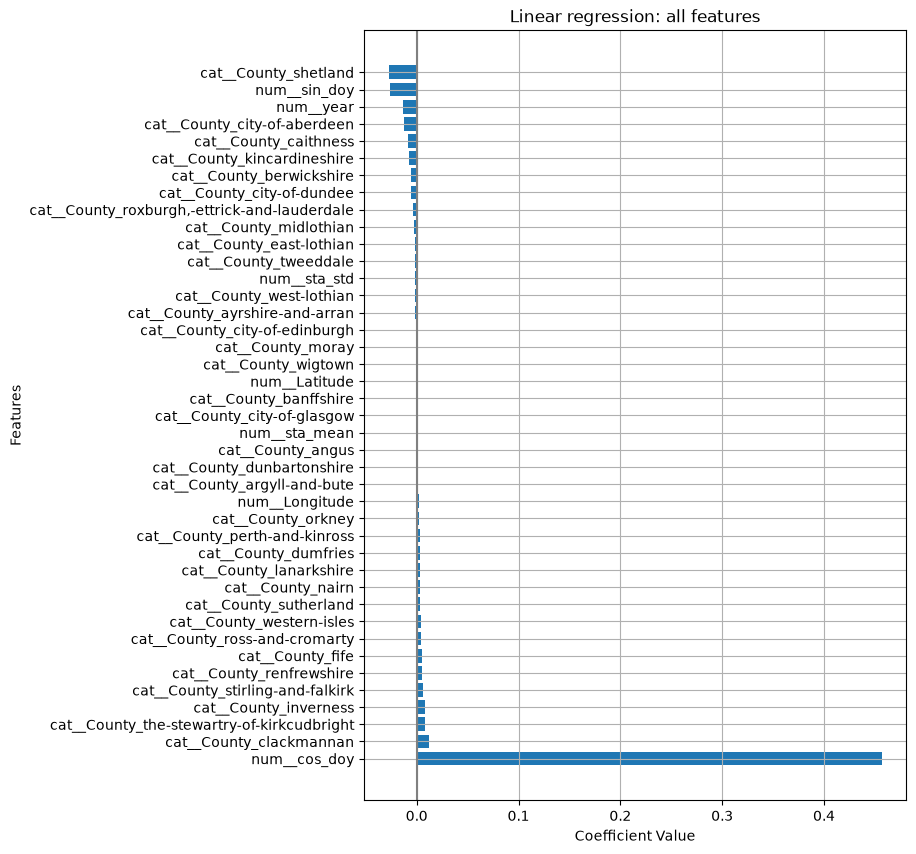

                                         feature      coef
2                                   num__cos_doy  0.456744
18                       cat__County_clackmannan  0.012248
37    cat__County_the-stewartry-of-kirkcudbright  0.007975
23                         cat__County_inverness  0.007948
35              cat__County_stirling-and-falkirk  0.005874
31                      cat__County_renfrewshire  0.005077
22                              cat__County_fife  0.004729
32                 cat__County_ross-and-cromarty  0.004176
40                     cat__County_western-isles  0.004064
36                        cat__County_sutherland  0.003479
28                             cat__County_nairn  0.003405
25                       cat__County_lanarkshire  0.003108
19                          cat__County_dumfries  0.002879
30                 cat__County_perth-and-kinross  0.002774
29                            cat__County_orkney  0.002603
4                                 num__Longitude  0.0021

In [117]:

river_feat["year"] = river_feat["date"].dt.year
num_cols = ["sin_doy", "cos_doy", "Latitude", "Longitude", "year", "sta_mean", "sta_std"]
cat_cols = ["County"]
X_train, y_train, X_test, y_test = make_split(river_feat, feature_cols = num_cols + cat_cols, target = "z")
preprocess = ColumnTransformer([("num", StandardScaler(), num_cols),
                                ("cat", OneHotEncoder(drop = "first"), cat_cols)])
lm_all = make_pipeline(preprocess, LinearRegression()).fit(X_train, y_train)
w_all = get_coefs(lm_all, plot = True, figsize = (7, 10), figtitle = "Linear regression: all features", intercept = False)
print(w_all)

In [118]:
pred_z_all = lm_all.predict(X_test)
pred_m_all = pred_z_all * test_df["sta_std"] + test_df["sta_mean"]

print("All features  RMSE (z):", root_mean_squared_error(y_test, pred_z_all))
print("All features  RMSE (m):", root_mean_squared_error(test_df["avg"], pred_m_all))
print("All features  MAE (m): ", mean_absolute_error(test_df["avg"], pred_m_all))

All features  RMSE (z): 0.7680974189264875
All features  RMSE (m): 0.18868058132098017
All features  MAE (m):  0.1357712419532196
